# Install Packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns
import re
import scipy.optimize as scpy

# modules to support in non-linear fitting
import statsmodels.api as sm
from ISLP.models import (summarize,
    poly,
    ModelSpec as MS)
from statsmodels.stats.anova import anova_lm

plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600

import warnings
warnings.filterwarnings('ignore')

# Colormap and BBB Initialization

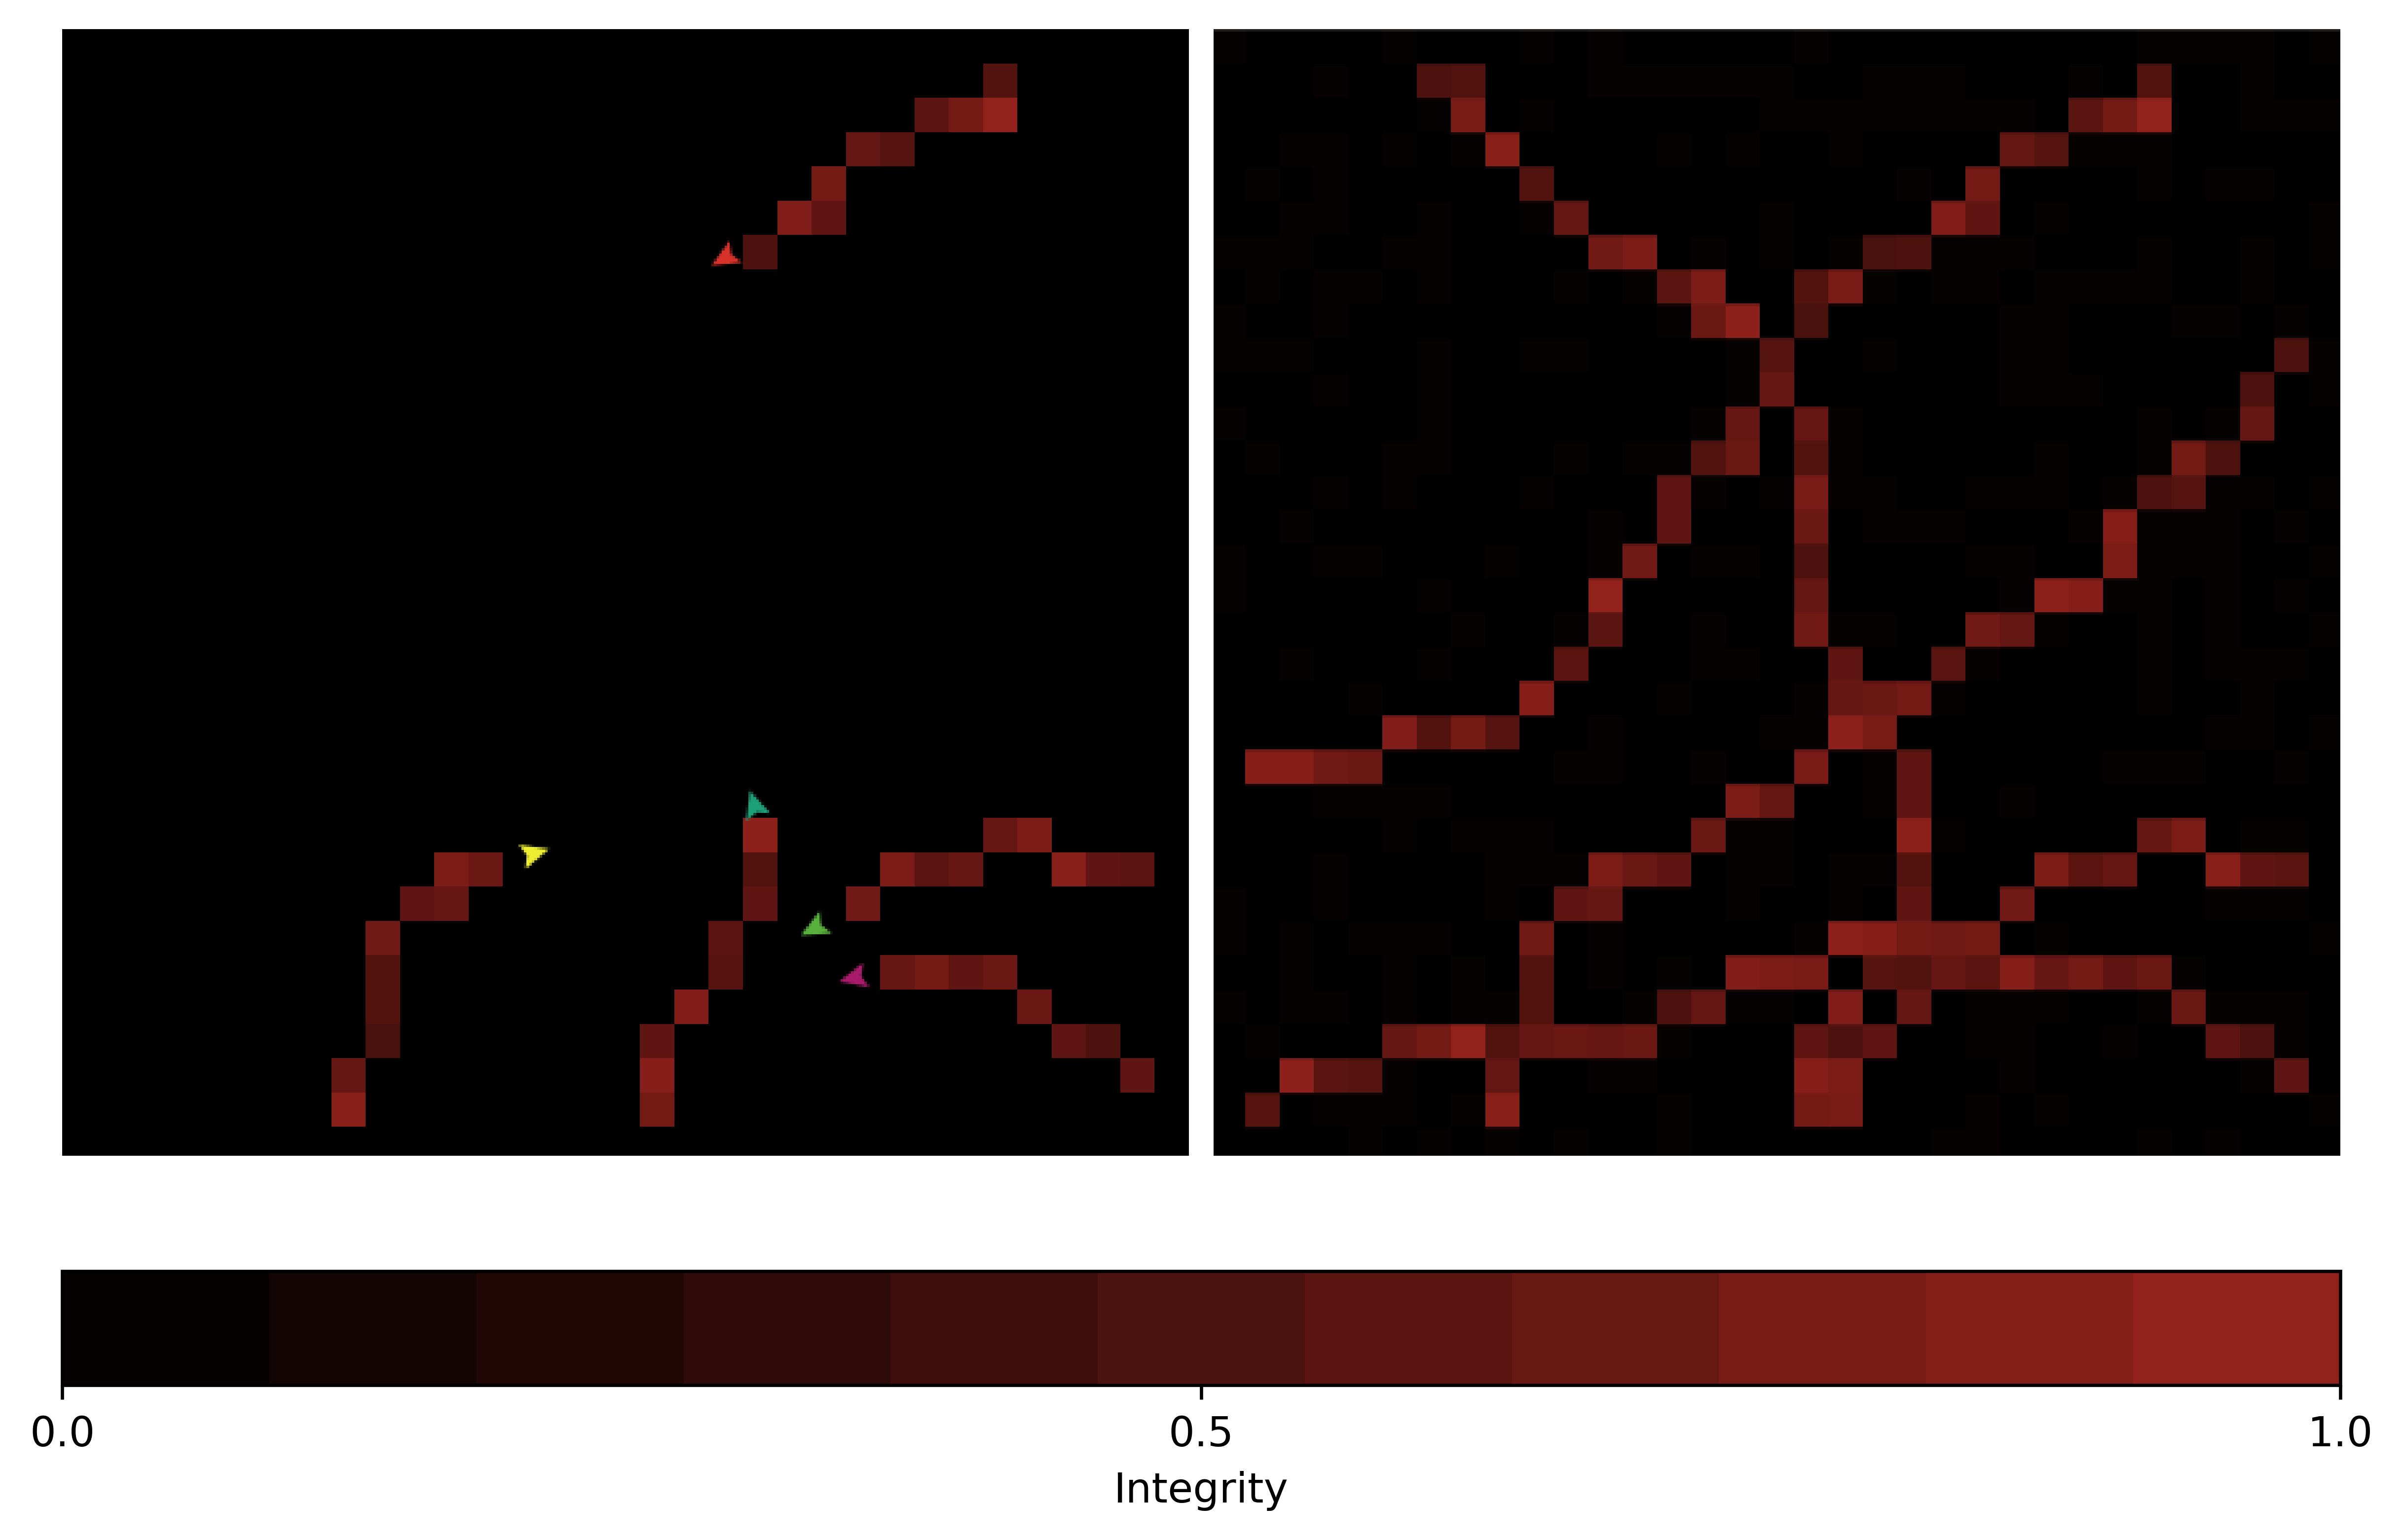

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(8, 8), layout='constrained')

# colors extrapolated from default NetLogo Color Swatches
cmap = mpl.colors.ListedColormap(['#050201', '#130504', '#210806', '#2f0b09', '#3d0e0b', '#4c120e',
                                  '#5a1511', '#681813', '#761b16', '#841e18', '#92211b'])

axs[0].imshow(np.asarray(Image.open('sim_pics/bbb-init-1.png')))
axs[1].imshow(np.asarray(Image.open('sim_pics/bbb-init-2.png')))

axs[0].axis('off')
axs[1].axis('off')

plt.colorbar(
    mpl.cm.ScalarMappable(cmap=cmap),
    ax=axs.ravel().tolist(),
    ticks = [0, 0.5, 1],
    orientation='horizontal',
    spacing='proportional',
    label='Integrity',
)

# Main Experiment Figures

In [3]:
# constant value for the number of ticks in the simulation
tick_num_list = np.arange(0,8761)

# list of ticks represenented as day value
day_vals = [i/24 for i in tick_num_list]

In [4]:
# loading the data for each treatment

treatment_none = pd.read_csv("treatment_data/treatment_none.csv")
treatment_moderate = pd.read_csv("treatment_data/treatment_moderate.csv")
treatment_high = pd.read_csv("treatment_data/treatment_high.csv")

In [5]:
# obtaing the mean of each variable at each tick for all treatments
mean_ph_treatment_none = [treatment_none.loc[treatment_none["[step]"] == tick_num]["global-pH"].mean()  for tick_num in tick_num_list]
mean_plaque_percent_none = [treatment_none.loc[treatment_none["[step]"] == tick_num]["Aβ %"].mean()  for tick_num in tick_num_list]
mean_integrity_none = [treatment_none.loc[treatment_none["[step]"] == tick_num]["global-integrity"].mean()  for tick_num in tick_num_list]

mean_ph_treatment_moderate = [treatment_moderate.loc[treatment_moderate["[step]"] == tick_num]["global-pH"].mean()  for tick_num in tick_num_list]
mean_plaque_percent_moderate = [treatment_moderate.loc[treatment_moderate["[step]"] == tick_num]["Aβ %"].mean()  for tick_num in tick_num_list]
mean_integrity_moderate = [treatment_moderate.loc[treatment_moderate["[step]"] == tick_num]["global-integrity"].mean()  for tick_num in tick_num_list]

mean_ph_treatment_high = [treatment_high.loc[treatment_high["[step]"] == tick_num]["global-pH"].mean()  for tick_num in tick_num_list]
mean_plaque_percent_high = [treatment_high.loc[treatment_high["[step]"] == tick_num]["Aβ %"].mean()  for tick_num in tick_num_list]
mean_integrity_high = [treatment_high.loc[treatment_high["[step]"] == tick_num]["global-integrity"].mean()  for tick_num in tick_num_list]

In [6]:
# create dataframes that hold the means respective to the day and variables

treatment_means = pd.DataFrame({
    'tick':tick_num_list,
    'day':day_vals,
    "mean_ph_none": mean_ph_treatment_none,
    "mean_plaque_percent_none": mean_plaque_percent_none,
    "mean_integrity_none": mean_integrity_none,

    "mean_ph_moderate": mean_ph_treatment_moderate,
    "mean_plaque_percent_moderate": mean_plaque_percent_moderate,
    "mean_integrity_moderate": mean_integrity_moderate,

    "mean_ph_high": mean_ph_treatment_high,
    "mean_plaque_percent_high": mean_plaque_percent_high,
    "mean_integrity_high": mean_integrity_high
})

In [7]:
# working dataframe
treatment_means.head()

,tick,day,mean_ph_none,mean_plaque_percent_none,mean_integrity_none,mean_ph_moderate,mean_plaque_percent_moderate,mean_integrity_moderate,mean_ph_high,mean_plaque_percent_high,mean_integrity_high
0,0,0.000000,7.3000,0.002755,75.131513,7.3000,0.002755,74.873571,7.3000,0.002755,75.037260
1,1,0.041667,7.2984,0.012562,75.131513,7.3000,0.012415,75.862323,7.2992,0.011607,76.028683
2,2,0.083333,7.2960,0.012562,75.132523,7.2968,0.012342,75.863632,7.2944,0.011534,76.029473
3,3,0.125000,7.2896,0.012562,75.133074,7.2944,0.012342,75.864964,7.2912,0.011387,76.030185
4,4,0.166667,7.2856,0.012525,75.135279,7.2904,0.012342,75.867365,7.2824,0.011276,76.032673


In [8]:
# List of custom colors to have consistent colors
colors = ['grey', 'darkgreen', 'darkorange']  

# Create a seaborn color palette from the list. This will allow for consistent colors in the plots
sns.set_palette(colors)

In [9]:
# list of the treatment variable fields
treatment_vars = treatment_means.columns[2:]

# Create Polynomial Fits

In [10]:
# creating a grid for the day values 

day_grid = np.linspace(treatment_means.day.min(),
                      treatment_means.day.max(),
                      365)

day_df = pd.DataFrame({'day':day_grid})

In [11]:
# Obtain the model fit for `mean_ph_none`

response_mean_ph_none = treatment_means['mean_ph_none']
    
# creating the basis functions(i.e X, X^2, X^3,...,X^ph_degree)

poly_cubic_model_mean_ph_none = MS([poly("day",degree=12)]).fit(treatment_means)
# obtain the design matrix after applying the polynomial regression model
        
design_mat_treatment_ph_none_means = poly_cubic_model_mean_ph_none.transform(treatment_means)
# fit a least squares model to the polynomial terms

ls_cubic_model_mean_ph_none = sm.OLS(response_mean_ph_none,design_mat_treatment_ph_none_means).fit()



# Obtain a design matrix from applying the given set of basis
design_mat_mean_ph_none = poly_cubic_model_mean_ph_none.transform(treatment_means)
# Design matrix of the grid
design_grid_mean_ph_none  = poly_cubic_model_mean_ph_none.transform(day_df)
# create a linear regression model to a non-linear variable with design_mat
M_mean_ph_none = sm.OLS(response_mean_ph_none, design_mat_treatment_ph_none_means).fit() 
# obtain the estimates by applying the model to the grid 
estimates_mean_ph_none = M_mean_ph_none.get_prediction(design_grid_mean_ph_none)

# ----------------------------------------------------------------------

    
# Obtain the model fit for `mean_ph_moderate`
    
response_mean_ph_moderate = treatment_means['mean_ph_moderate']

# creating the basis functions(i.e X, X^2, X^3,...,X^ph_degree)

poly_cubic_model_mean_ph_moderate = MS([poly("day", degree=12)]).fit(treatment_means)
# obtain the design matrix after applying the polynomial regression model

design_mat_treatment_ph_moderate_means = poly_cubic_model_mean_ph_moderate.transform(treatment_means)
# fit a least squares model to the polynomial terms

ls_cubic_model_mean_ph_moderate = sm.OLS(response_mean_ph_moderate, design_mat_treatment_ph_moderate_means).fit()

# Obtain a design matrix from applying the given set of basis
design_mat_mean_ph_moderate = poly_cubic_model_mean_ph_moderate.transform(treatment_means)
# Design matrix of the grid
design_grid_mean_ph_moderate = poly_cubic_model_mean_ph_moderate.transform(day_df)
# create a linear regression model to a non-linear variable with design_mat
M_mean_ph_moderate = sm.OLS(response_mean_ph_moderate, design_mat_treatment_ph_moderate_means).fit() 
# obtain the estimates by applying the model to the grid 
estimates_mean_ph_moderate = M_mean_ph_moderate.get_prediction(design_grid_mean_ph_moderate)


# ----------------------------------------------------------------------


# Obtain the model fit for `mean_ph_high`

response_mean_ph_high = treatment_means['mean_ph_high']
        
# creating the basis functions(i.e X, X^2, X^3,...,X^ph_degree)

poly_cubic_model_mean_ph_high = MS([poly("day", degree=12)]).fit(treatment_means)
# obtain the design matrix after applying the polynomial regression model

design_mat_treatment_ph_high_means = poly_cubic_model_mean_ph_high.transform(treatment_means)
# fit a least squares model to the polynomial terms

ls_cubic_model_mean_ph_high = sm.OLS(response_mean_ph_high, design_mat_treatment_ph_high_means).fit()

# Obtain a design matrix from applying the given set of basis
design_mat_mean_ph_high = poly_cubic_model_mean_ph_high.transform(treatment_means)
# Design matrix of the grid
design_grid_mean_ph_high = poly_cubic_model_mean_ph_high.transform(day_df)
# create a linear regression model to a non-linear variable with design_mat
M_mean_ph_high = sm.OLS(response_mean_ph_high, design_mat_treatment_ph_high_means).fit() 
# obtain the estimates by applying the model to the grid 
estimates_mean_ph_high = M_mean_ph_high.get_prediction(design_grid_mean_ph_high)

# ----------------------------------------------------------------------


# Obtain the model fit for `mean_integrity_none`

response_mean_integrity_none = treatment_means['mean_integrity_none']
    
# creating the basis functions(i.e X, X^2, X^integrity_degree)

poly_cubic_model_mean_integrity_none = MS([poly("day", degree=3)]).fit(treatment_means)
# obtain the design matrix after applying the polynomial regression model

design_mat_treatment_integrity_none_means = poly_cubic_model_mean_integrity_none.transform(treatment_means)
# fit a least squares model to the polynomial terms

ls_cubic_model_mean_integrity_none = sm.OLS(response_mean_integrity_none, design_mat_treatment_integrity_none_means).fit()

# Obtain a design matrix from applying the given set of basis
design_mat_mean_integrity_none = poly_cubic_model_mean_integrity_none.transform(treatment_means)
# Design matrix of the grid
design_grid_mean_integrity_none = poly_cubic_model_mean_integrity_none.transform(day_df)
# create a linear regression model to a non-linear variable with design_mat
M_mean_integrity_none = sm.OLS(response_mean_integrity_none, design_mat_treatment_integrity_none_means).fit() 
# obtain the estimates by applying the model to the grid 
estimates_mean_integrity_none = M_mean_integrity_none.get_prediction(design_grid_mean_integrity_none)

# ----------------------------------------------------------------------


# Obtain the model fit for `mean_integrity_moderate`

response_mean_integrity_moderate = treatment_means['mean_integrity_moderate']
    
# creating the basis functions(i.e X, X^2, X^integrity_degree)

poly_cubic_model_mean_integrity_moderate = MS([poly("day", degree=3)]).fit(treatment_means)
# obtain the design matrix after applying the polynomial regression model

design_mat_treatment_integrity_moderate_means = poly_cubic_model_mean_integrity_moderate.transform(treatment_means)
# fit a least squares model to the polynomial terms

ls_cubic_model_mean_integrity_moderate = sm.OLS(response_mean_integrity_moderate, design_mat_treatment_integrity_moderate_means).fit()

# Obtain a design matrix from applying the given set of basis
design_mat_mean_integrity_moderate = poly_cubic_model_mean_integrity_moderate.transform(treatment_means)
# Design matrix of the grid
design_grid_mean_integrity_moderate = poly_cubic_model_mean_integrity_moderate.transform(day_df)
# create a linear regression model to a non-linear variable with design_mat
M_mean_integrity_moderate = sm.OLS(response_mean_integrity_moderate, design_mat_treatment_integrity_moderate_means).fit() 
# obtain the estimates by applying the model to the grid 
estimates_mean_integrity_moderate = M_mean_integrity_moderate.get_prediction(design_grid_mean_integrity_moderate)


# ----------------------------------------------------------------------


# Obtain the model fit for `mean_integrity_high`

response_mean_integrity_high = treatment_means['mean_integrity_high']
    
# creating the basis functions(i.e X, X^2, X^integrity_degree)

poly_cubic_model_mean_integrity_high = MS([poly("day", degree=3)]).fit(treatment_means)
# obtain the design matrix after applying the polynomial regression model

design_mat_treatment_integrity_high_means = poly_cubic_model_mean_integrity_high.transform(treatment_means)
# fit a least squares model to the polynomial terms

ls_cubic_model_mean_integrity_high = sm.OLS(response_mean_integrity_high, design_mat_treatment_integrity_high_means).fit()

# Obtain a design matrix from applying the given set of basis
design_mat_mean_integrity_high = poly_cubic_model_mean_integrity_high.transform(treatment_means)
# Design matrix of the grid
design_grid_mean_integrity_high = poly_cubic_model_mean_integrity_high.transform(day_df)
# create a linear regression model to a non-linear variable with design_mat
M_mean_integrity_high = sm.OLS(response_mean_integrity_high, design_mat_treatment_integrity_high_means).fit() 
# obtain the estimates by applying the model to the grid 
estimates_mean_integrity_high = M_mean_integrity_high.get_prediction(design_grid_mean_integrity_high)

# Create Logistic Fit

In [12]:
# Define the logistic function
def logistic(x, L, k, x0):
    """
    series, float, float, float -> series

    Expects the time series values, the maximum value, the growth rate, and the midpoint
    returns a series of values that correspond the growth of the Aβ plaques

    """
     # return the value of the logistic fucntion
    return L / (1 + np.exp(-k * (x - x0)))

In [13]:
# get plaque variables
vars_plaque = [re.search(".*plaque.*",field).group() for field in treatment_vars if re.search(".*plaque.*",field) != None]

In [14]:
# storing relevant data

# time frame 
time_frame = treatment_means.day

# store all the response variables and their observations

response_variables = [treatment_means[treatment_var] for treatment_var in vars_plaque]

# store all max values of the response variables

response_variables_maxes = [treatment_means[treatment_var].max() for treatment_var in vars_plaque]

# store all mid points

response_variables_mid_points = [response_variable_max/2 for response_variable_max in response_variables_maxes]

In [15]:
# obtain the coefficients for L,k, and x0 for the response variables

coefficients_for_vars = [scpy.curve_fit(logistic,time_frame,response_variable, p0=[max_val,1,mid_point],maxfev=10000)[0]
                         for response_variable,max_val,mid_point in zip(response_variables,response_variables_maxes,response_variables_mid_points)]

In [16]:
# fit the coefficients in the logistic fucntion to obtain the estimates
fitted_values = [logistic(time_frame,coefficients_for_vars[i][0],coefficients_for_vars[i][1],coefficients_for_vars[i][2]) for i in np.arange(len(coefficients_for_vars))]

In [17]:
fitted_values

[0       0.013777
 1       0.013784
 2       0.013791
 3       0.013799
 4       0.013806
           ...   
 8756    0.385314
 8757    0.385369
 8758    0.385424
 8759    0.385479
 8760    0.385534
 Name: day, Length: 8761, dtype: float64,
 0       0.012116
 1       0.012121
 2       0.012125
 3       0.012130
 4       0.012134
           ...   
 8756    0.154448
 8757    0.154473
 8758    0.154497
 8759    0.154522
 8760    0.154547
 Name: day, Length: 8761, dtype: float64,
 0       0.008351
 1       0.008354
 2       0.008357
 3       0.008359
 4       0.008362
           ...   
 8756    0.080291
 8757    0.080303
 8758    0.080314
 8759    0.080326
 8760    0.080337
 Name: day, Length: 8761, dtype: float64]

# Plots

## Create pH Plot

In [18]:
sns.set_style('whitegrid')

Text(0, 0.5, 'Mean pH')

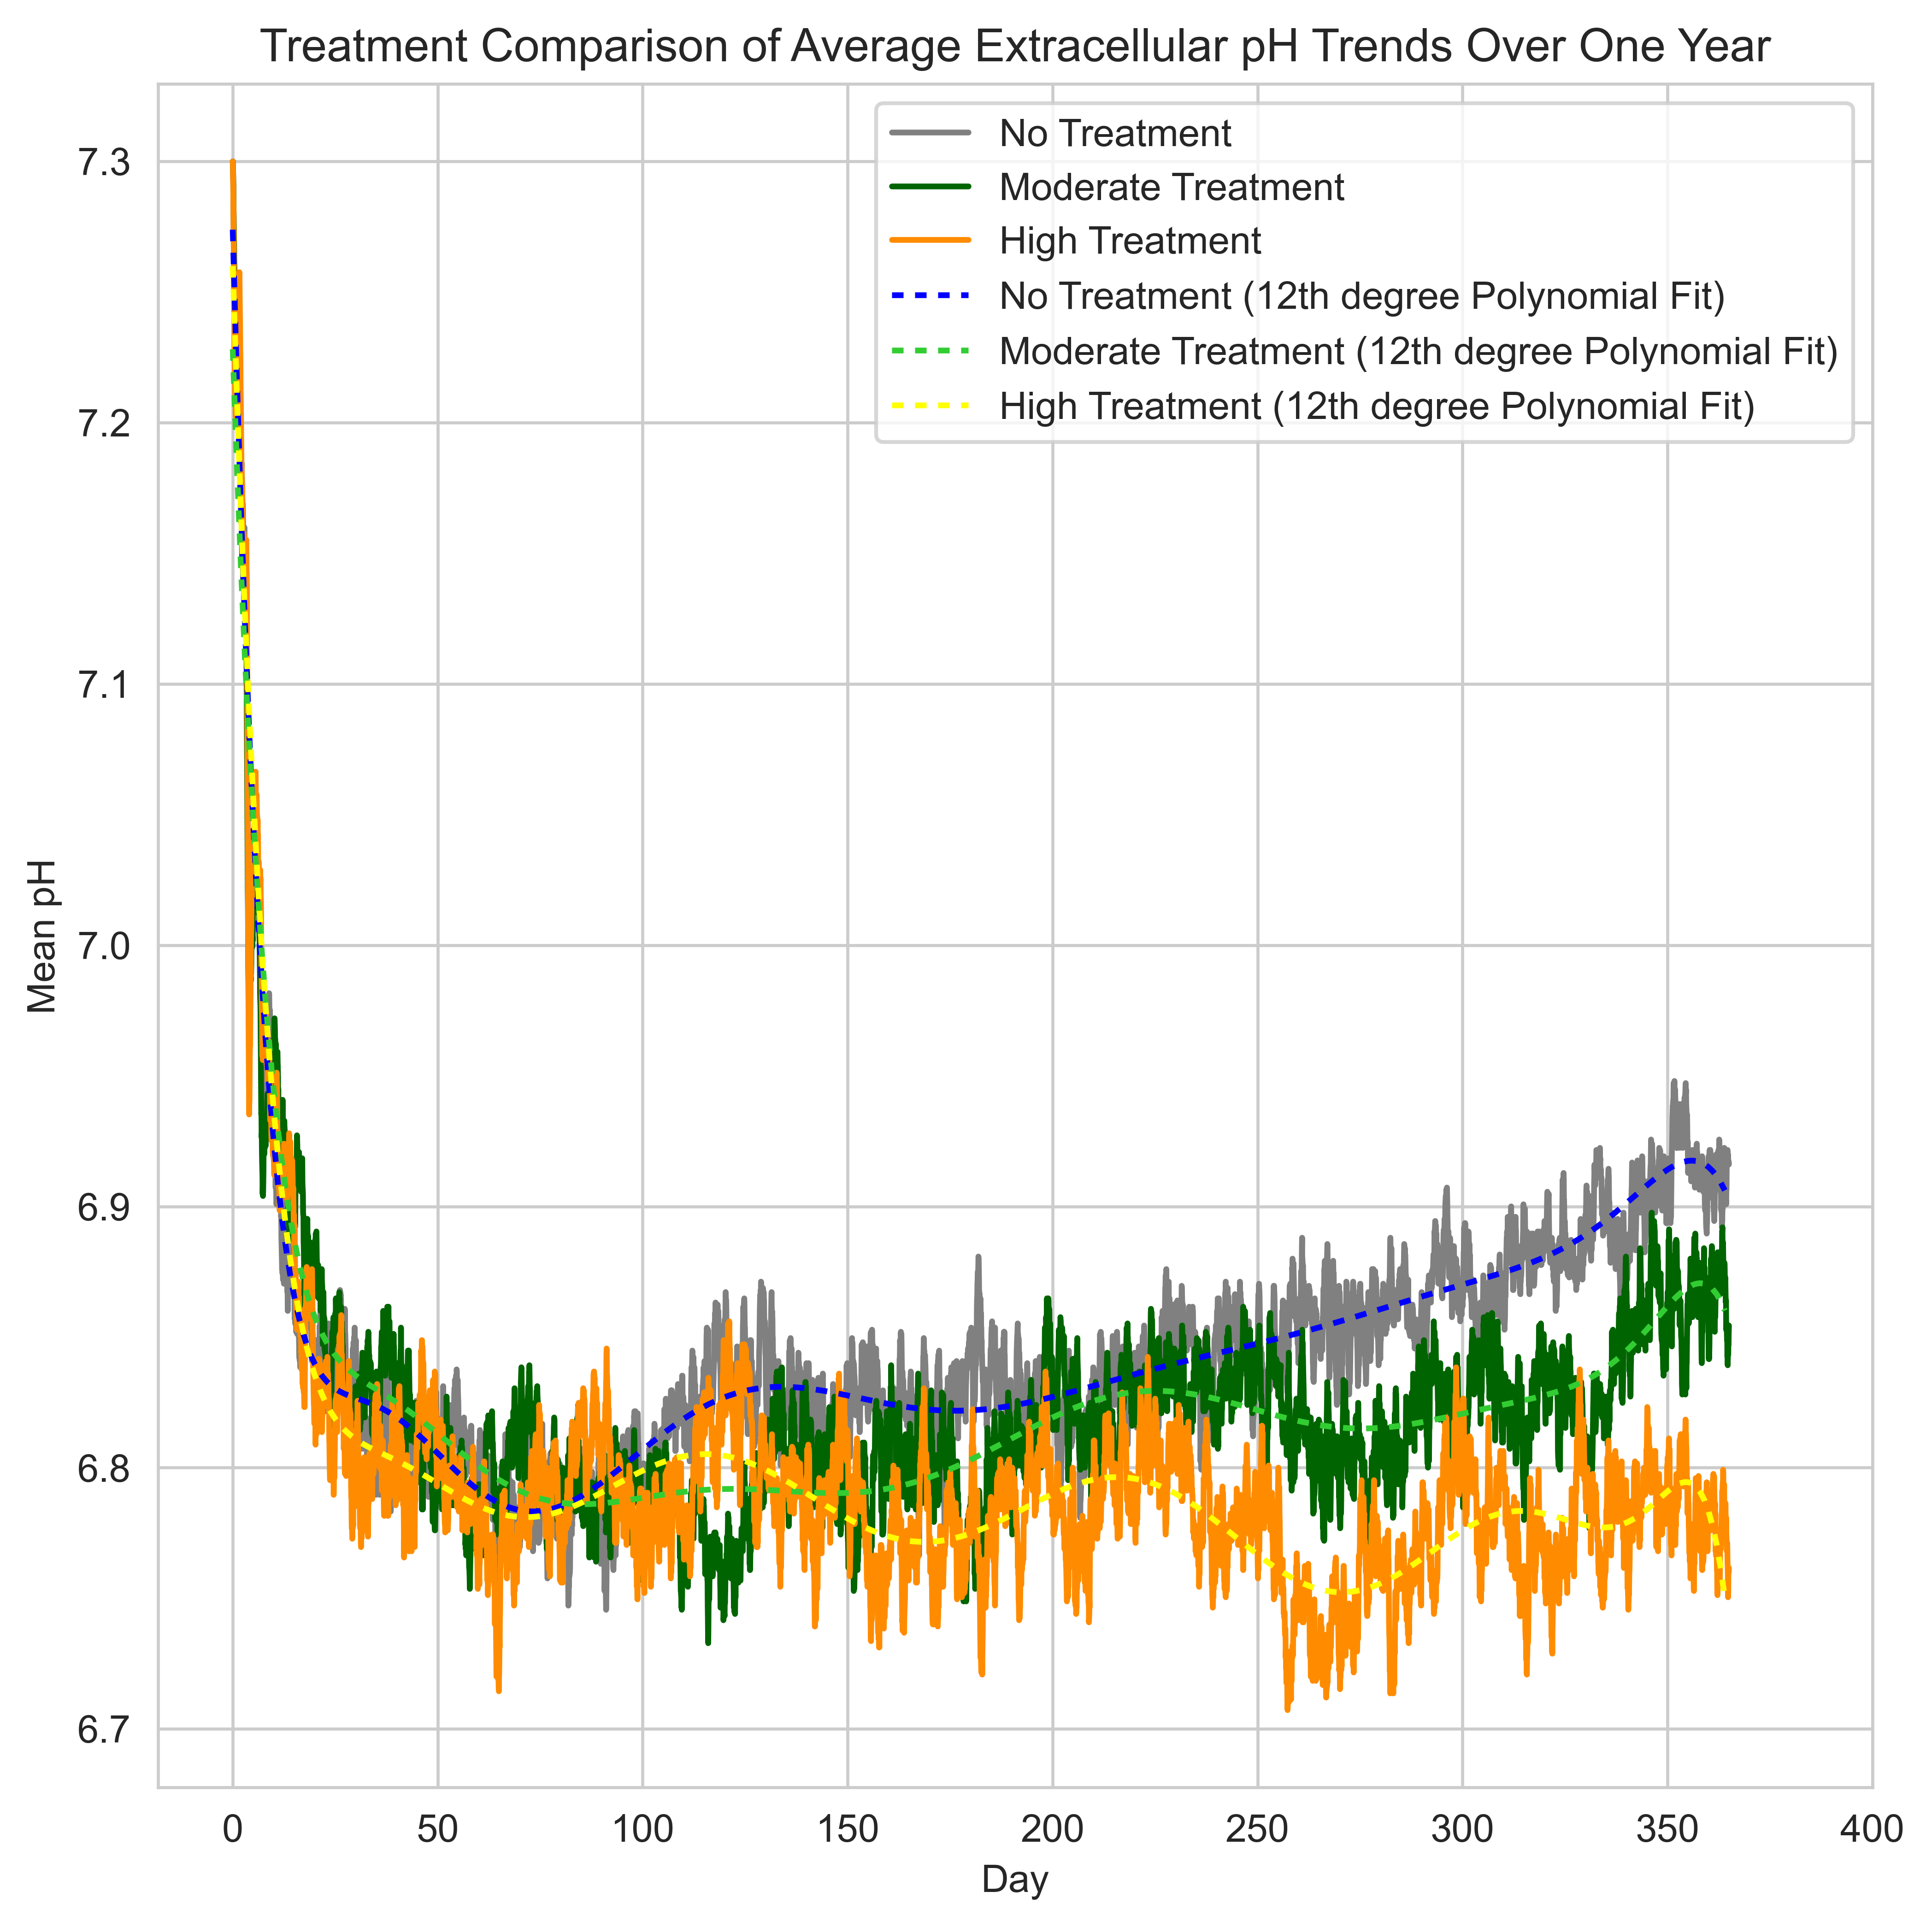

In [19]:
fig, ax = plt.subplots(figsize=(8,8))

# plot mean values for treatment intensities
sns.lineplot(data=treatment_means, x='day', y='mean_ph_none', label='No Treatment')
sns.lineplot(data=treatment_means, x='day', y='mean_ph_moderate', label='Moderate Treatment')
sns.lineplot(data=treatment_means, x='day', y='mean_ph_high', label='High Treatment')

# plot fitted regression lines for each treatment
sns.lineplot(data=estimates_mean_ph_none.predicted_mean, label='No Treatment (12th degree Polynomial Fit)', color='b', dashes=(2, 2))
sns.lineplot(data=estimates_mean_ph_moderate.predicted_mean, label='Moderate Treatment (12th degree Polynomial Fit)', color='limegreen', dashes=(2, 2))
sns.lineplot(data=estimates_mean_ph_high.predicted_mean, label='High Treatment (12th degree Polynomial Fit)', color='yellow', dashes=(2, 2))

plt.legend()

plt.title('Treatment Comparison of Average Extracellular pH Trends Over One Year')
plt.xticks(np.arange(0, 401, 50))
plt.xlabel('Day')
plt.ylabel('Mean pH')

## Create BBB Plot

Text(0, 0.5, 'Mean Integrity (%)')

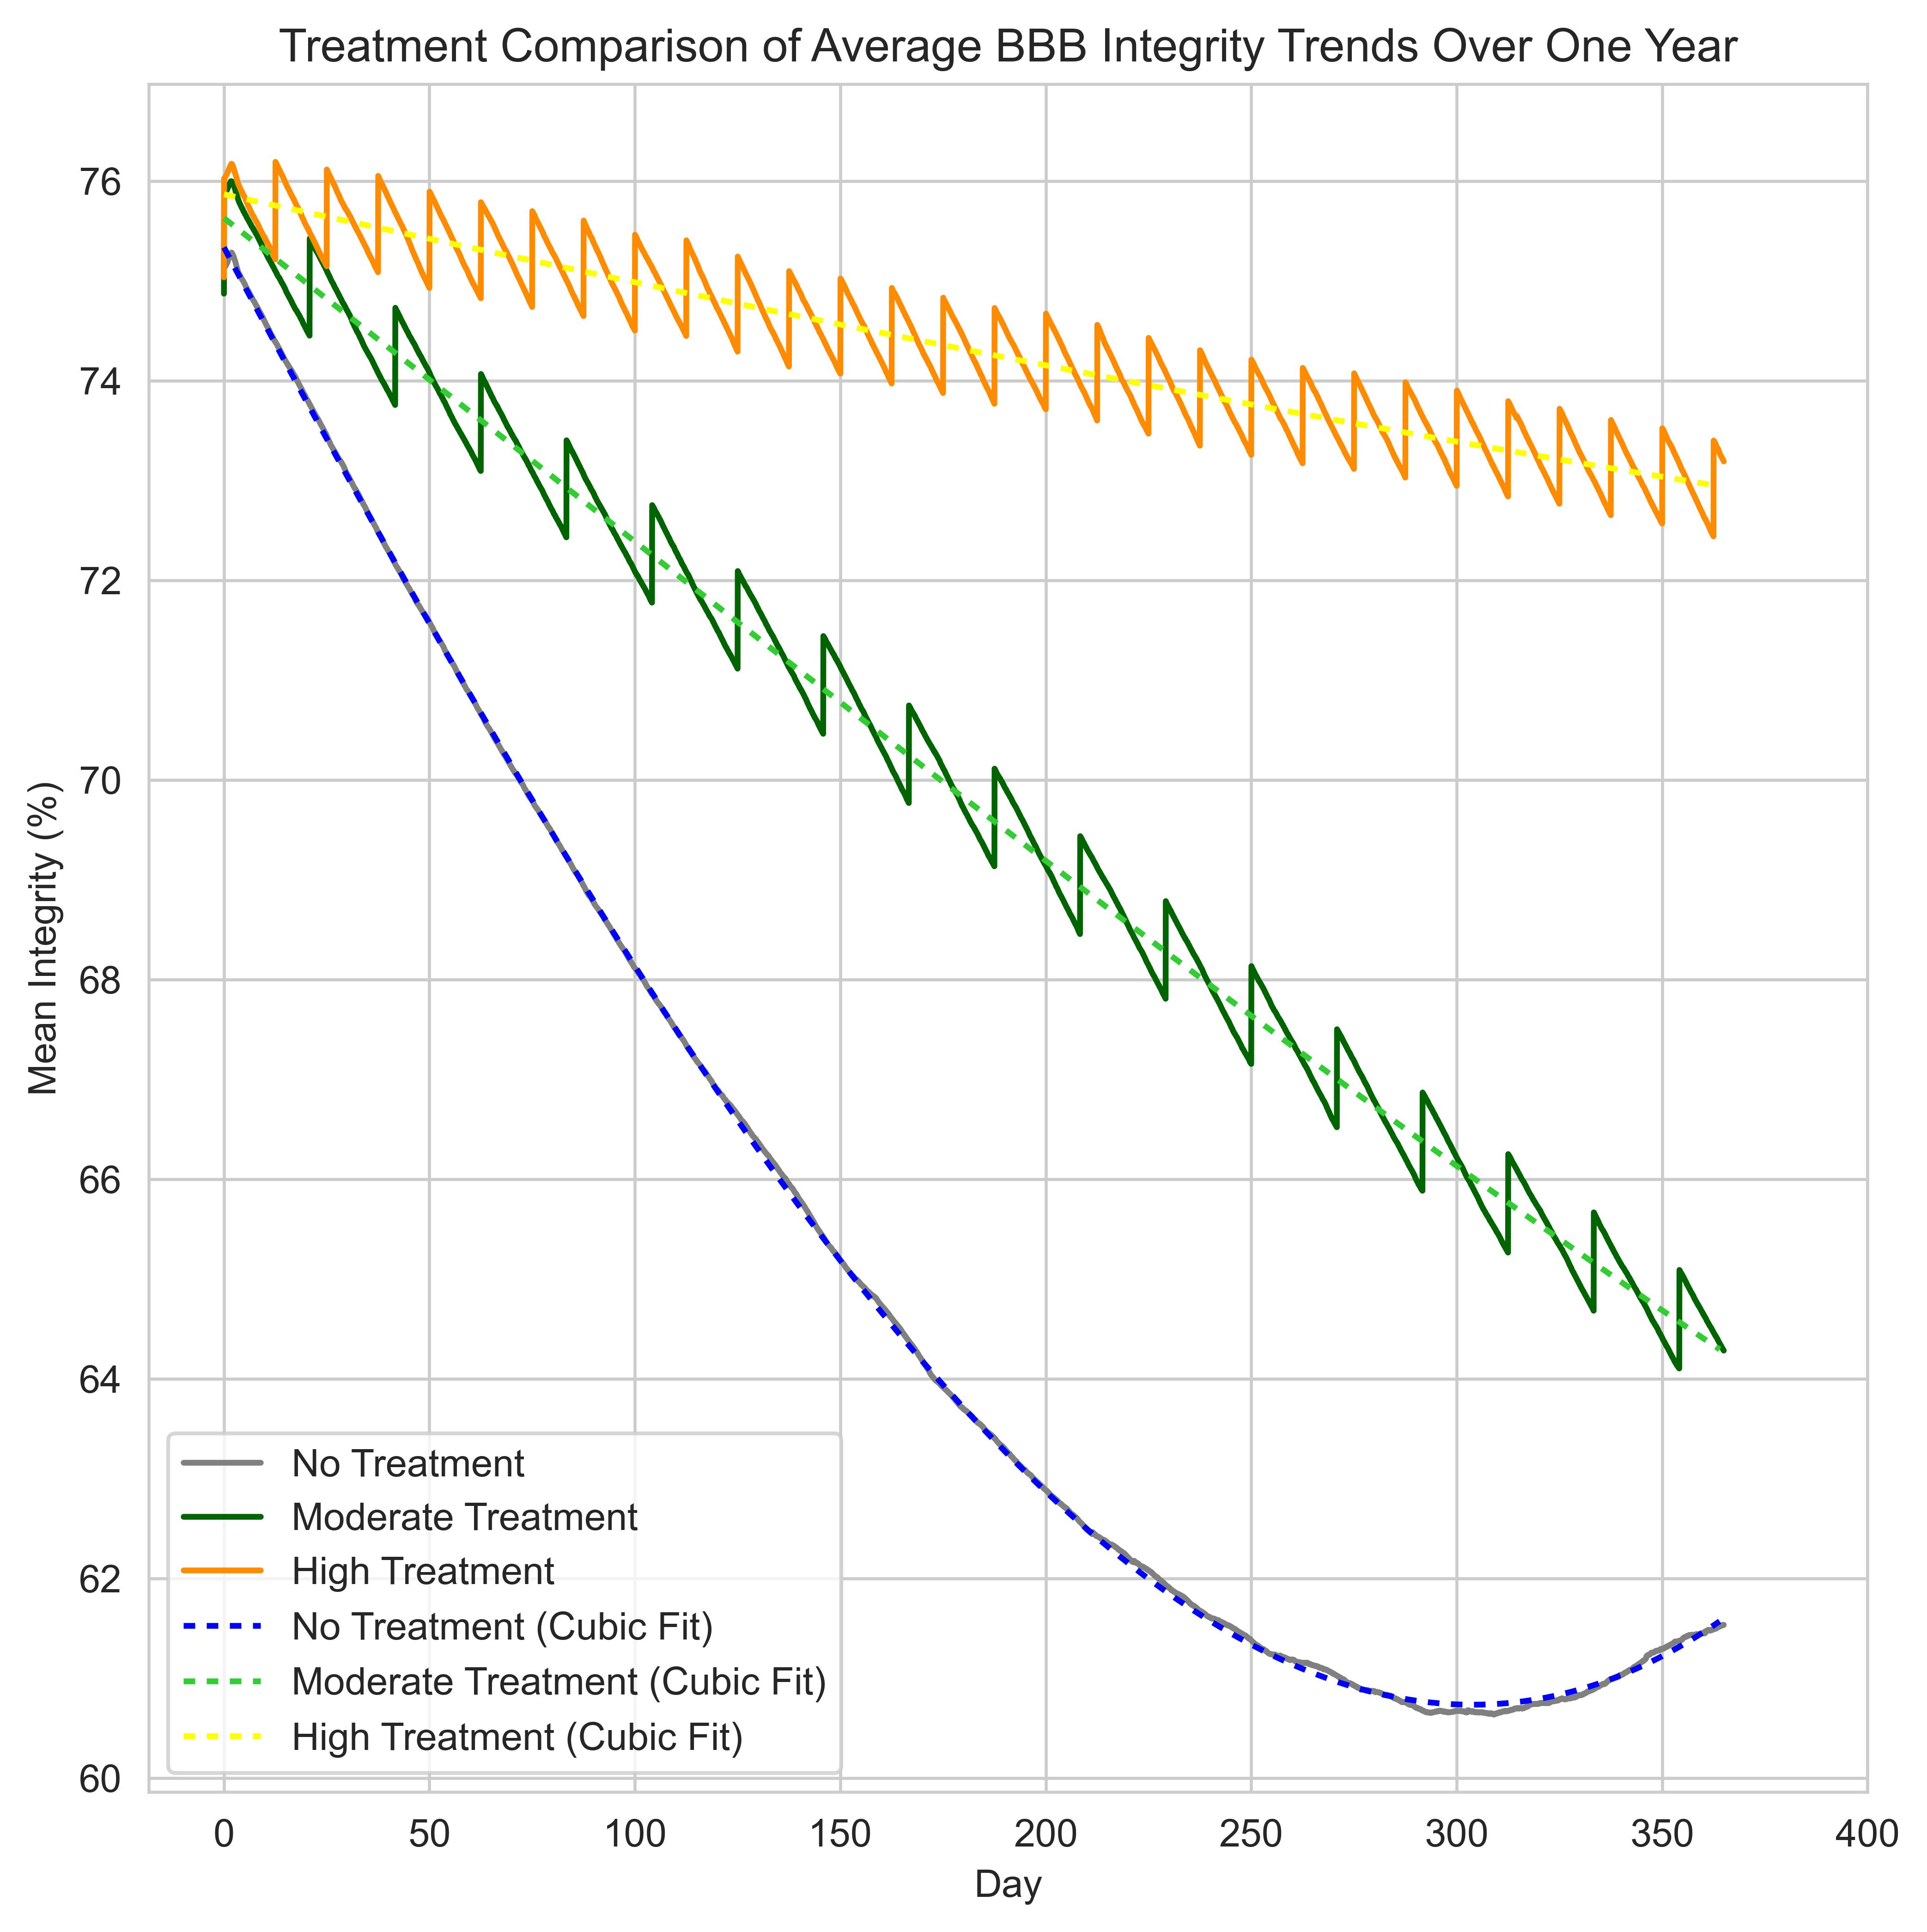

In [20]:
fig, ax = plt.subplots(figsize=(8,8))

# plot mean values for treatment intensities
sns.lineplot(data=treatment_means, x='day', y='mean_integrity_none', label='No Treatment')
sns.lineplot(data=treatment_means, x='day', y='mean_integrity_moderate', label='Moderate Treatment')
sns.lineplot(data=treatment_means, x='day', y='mean_integrity_high', label='High Treatment')

# plot fitted regression lines for each treatment
sns.lineplot(data=estimates_mean_integrity_none.predicted_mean, label='No Treatment (Cubic Fit)', color='b', dashes=(2, 2))
sns.lineplot(data=estimates_mean_integrity_moderate.predicted_mean, label='Moderate Treatment (Cubic Fit)', color='limegreen', dashes=(2, 2))
sns.lineplot(data=estimates_mean_integrity_high.predicted_mean, label='High Treatment (Cubic Fit)', color='yellow', dashes=(2, 2))

plt.legend()

plt.title('Treatment Comparison of Average BBB Integrity Trends Over One Year')
plt.xticks(np.arange(0, 401, 50))
plt.xlabel('Day')
plt.ylabel('Mean Integrity (%)')

## Create Plaque Coverage Plot

In [21]:
# fitted_plaque_plots =  [sns.lineplot(data= treatment_means,x='day', y=var) for var in fitted_values]

In [22]:
# fitted_plaque_plots

Text(0, 0.5, 'Mean Aβ')

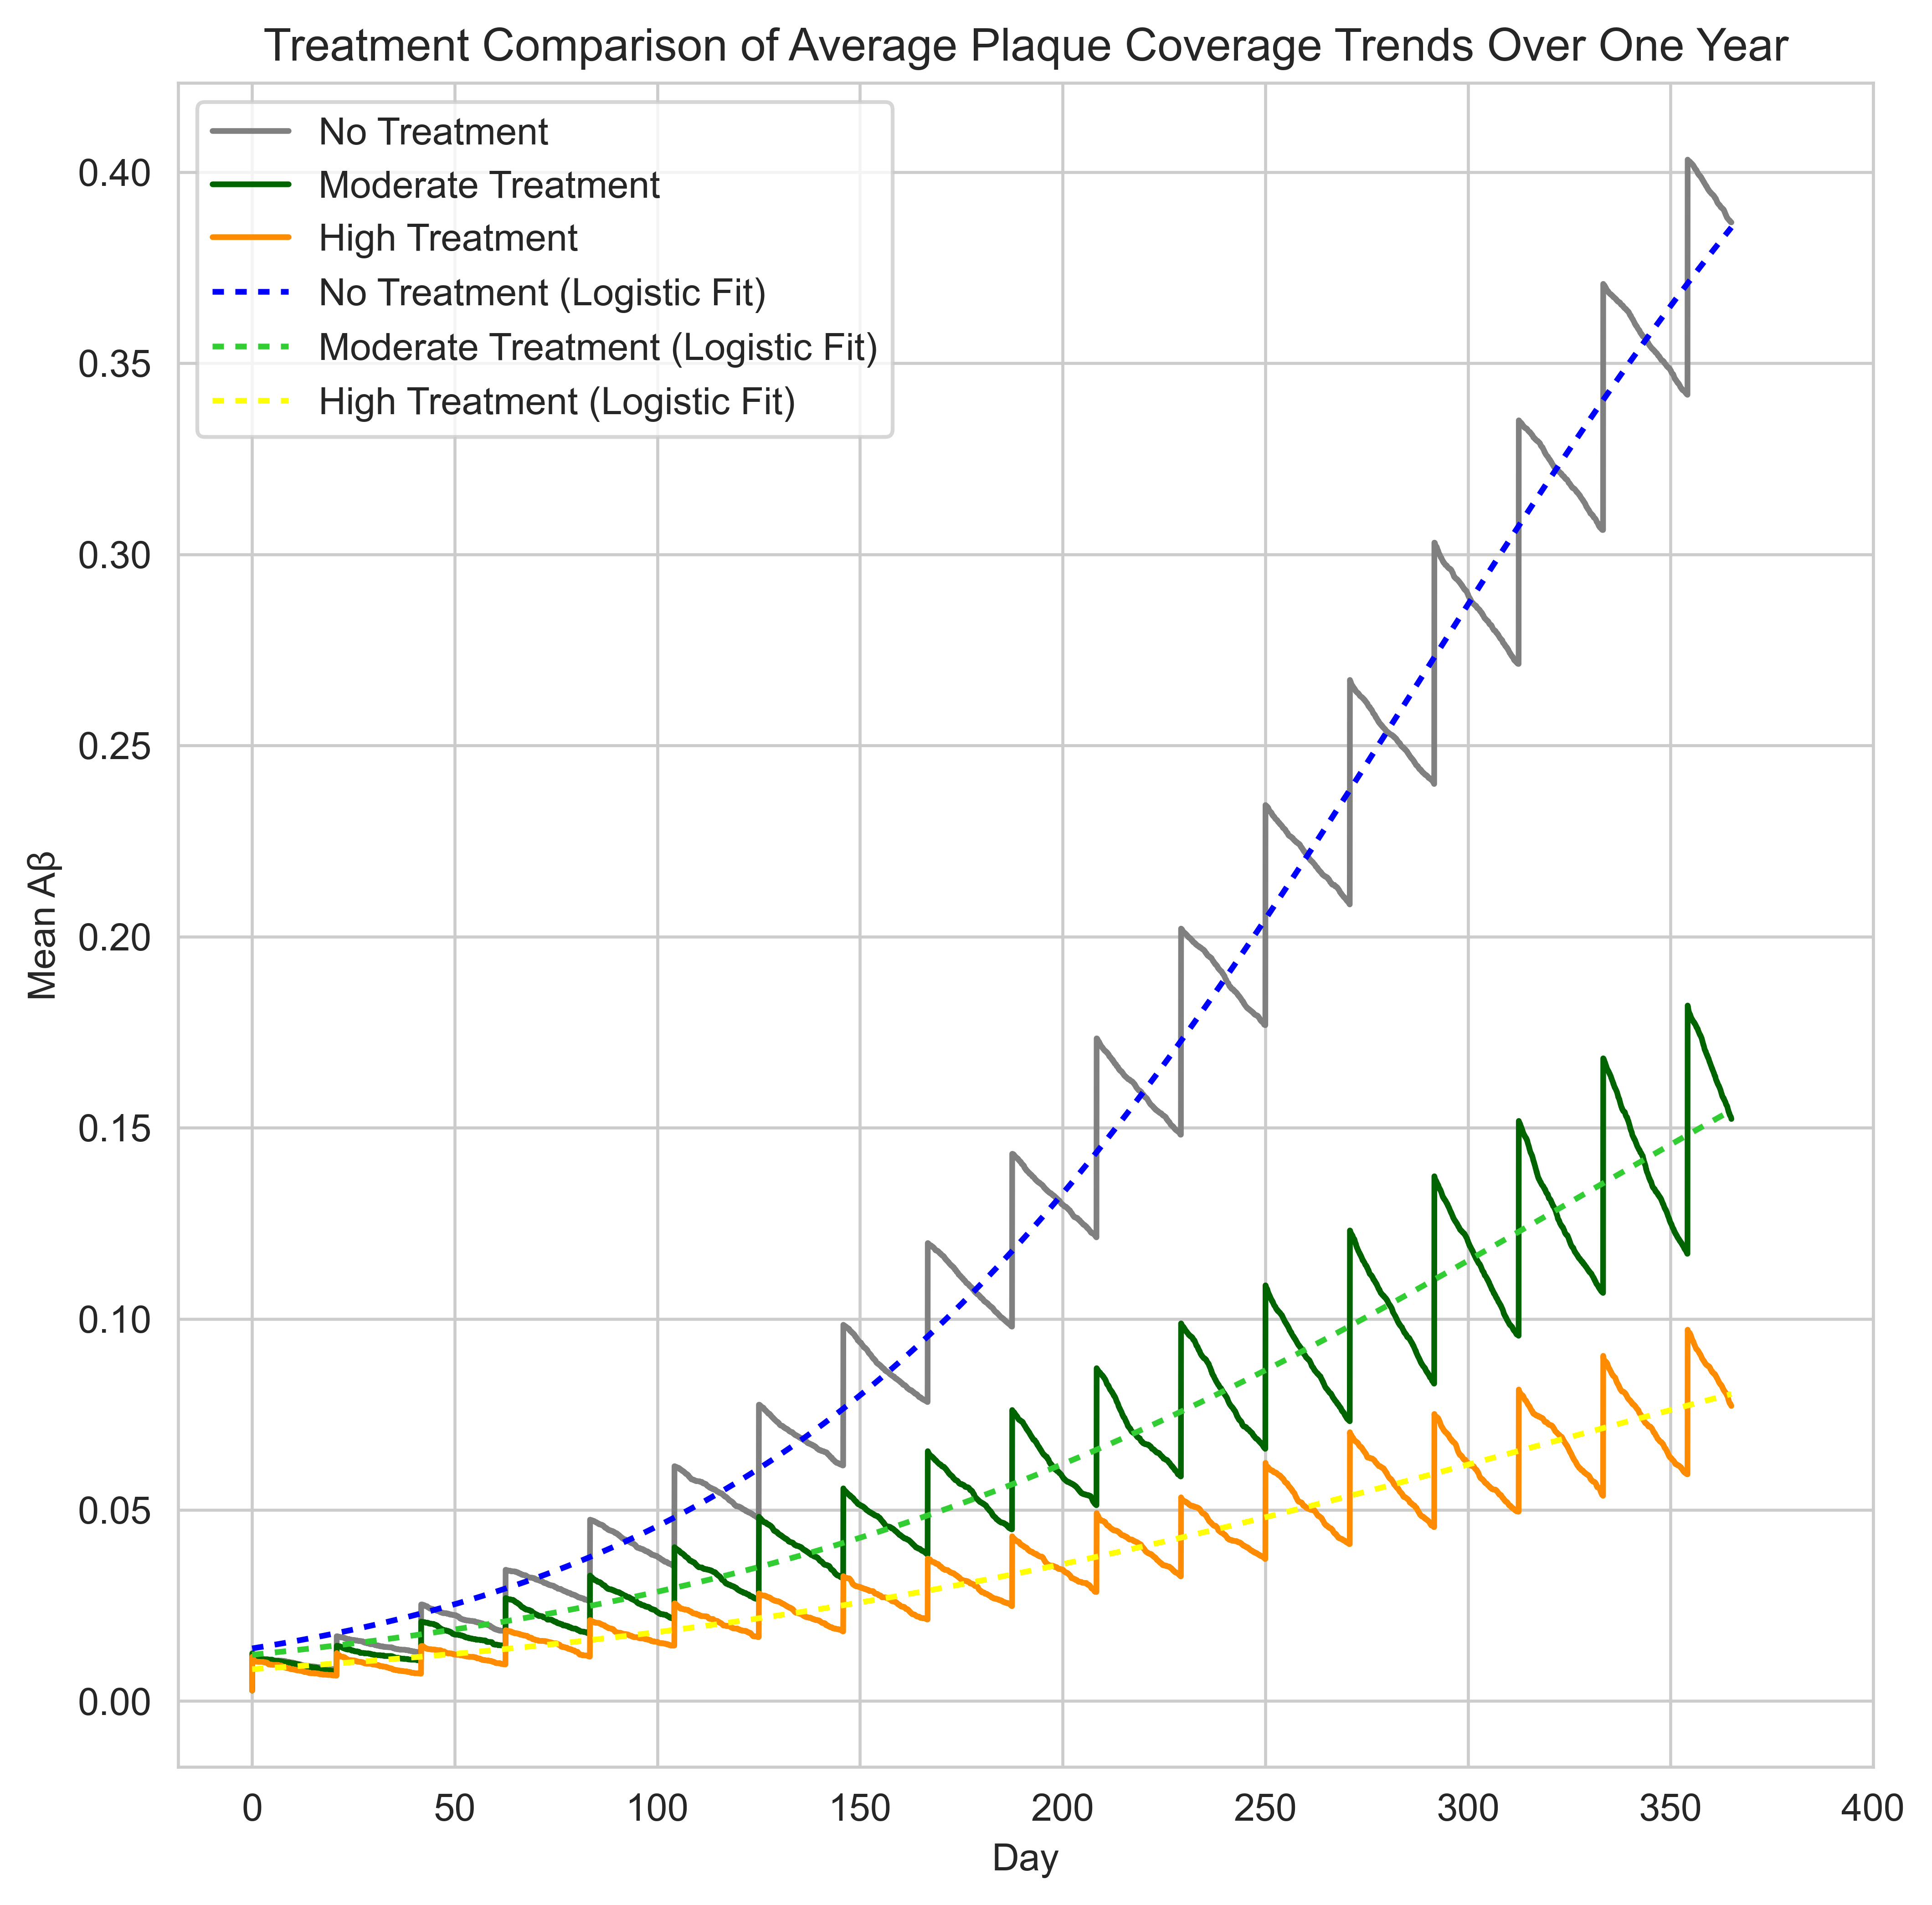

In [23]:
fig, ax = plt.subplots(figsize=(8,8))

# plot mean values for treatment intensities
sns.lineplot(data=treatment_means, x='day', y='mean_plaque_percent_none', label='No Treatment')
sns.lineplot(data=treatment_means, x='day', y='mean_plaque_percent_moderate', label='Moderate Treatment')
sns.lineplot(data=treatment_means, x='day', y='mean_plaque_percent_high', label='High Treatment')

# plot fitted regression lines for each treatment
sns.lineplot(data=treatment_means, x='day', y=fitted_values[0], label='No Treatment (Logistic Fit)', color='b', dashes=(2, 2))
sns.lineplot(data=treatment_means, x='day', y=fitted_values[1], label='Moderate Treatment (Logistic Fit)', color='limegreen', dashes=(2, 2))
sns.lineplot(data=treatment_means, x='day', y=fitted_values[2], label='High Treatment (Logistic Fit)', color='yellow', dashes=(2, 2))

plt.legend()

plt.title('Treatment Comparison of Average Plaque Coverage Trends Over One Year')
plt.xticks(np.arange(0, 401, 50))
plt.xlabel('Day')
plt.ylabel('Mean Aβ')

# BBB (Metabolic Booster Only)

In [24]:
met_df = pd.read_csv("met_only_data/booster_only.csv", skiprows=5, header=1)

In [25]:
# keep only columns related to BBB integrity and met booster amount
met_df = met_df.filter(items=["[run number]", "metabolic-booster", "[step]", "global-integrity"])

In [26]:
# split data into each metabolic booster intensity
none_df = met_df[met_df["metabolic-booster"] == "none"]
mid_df  = met_df[met_df["metabolic-booster"] == "twice per week"]
high_df = met_df[met_df["metabolic-booster"] == "daily"]

In [27]:
none_avg = [(none_df[none_df['[step]'] == i]['global-integrity']).mean() for i in tick_num_list]
mid_avg  = [(mid_df[mid_df['[step]'] == i]['global-integrity']).mean() for i in tick_num_list]
high_avg = [(high_df[high_df['[step]'] == i]['global-integrity']).mean() for i in tick_num_list]

In [28]:
# working dataframe for data analysis for the met booster data
plot_df = pd.DataFrame(
            {'ticks':tick_num_list,
             'day':day_vals,
             "none_mean":none_avg,
             "mid_mean":mid_avg,
             "high_mean":high_avg})

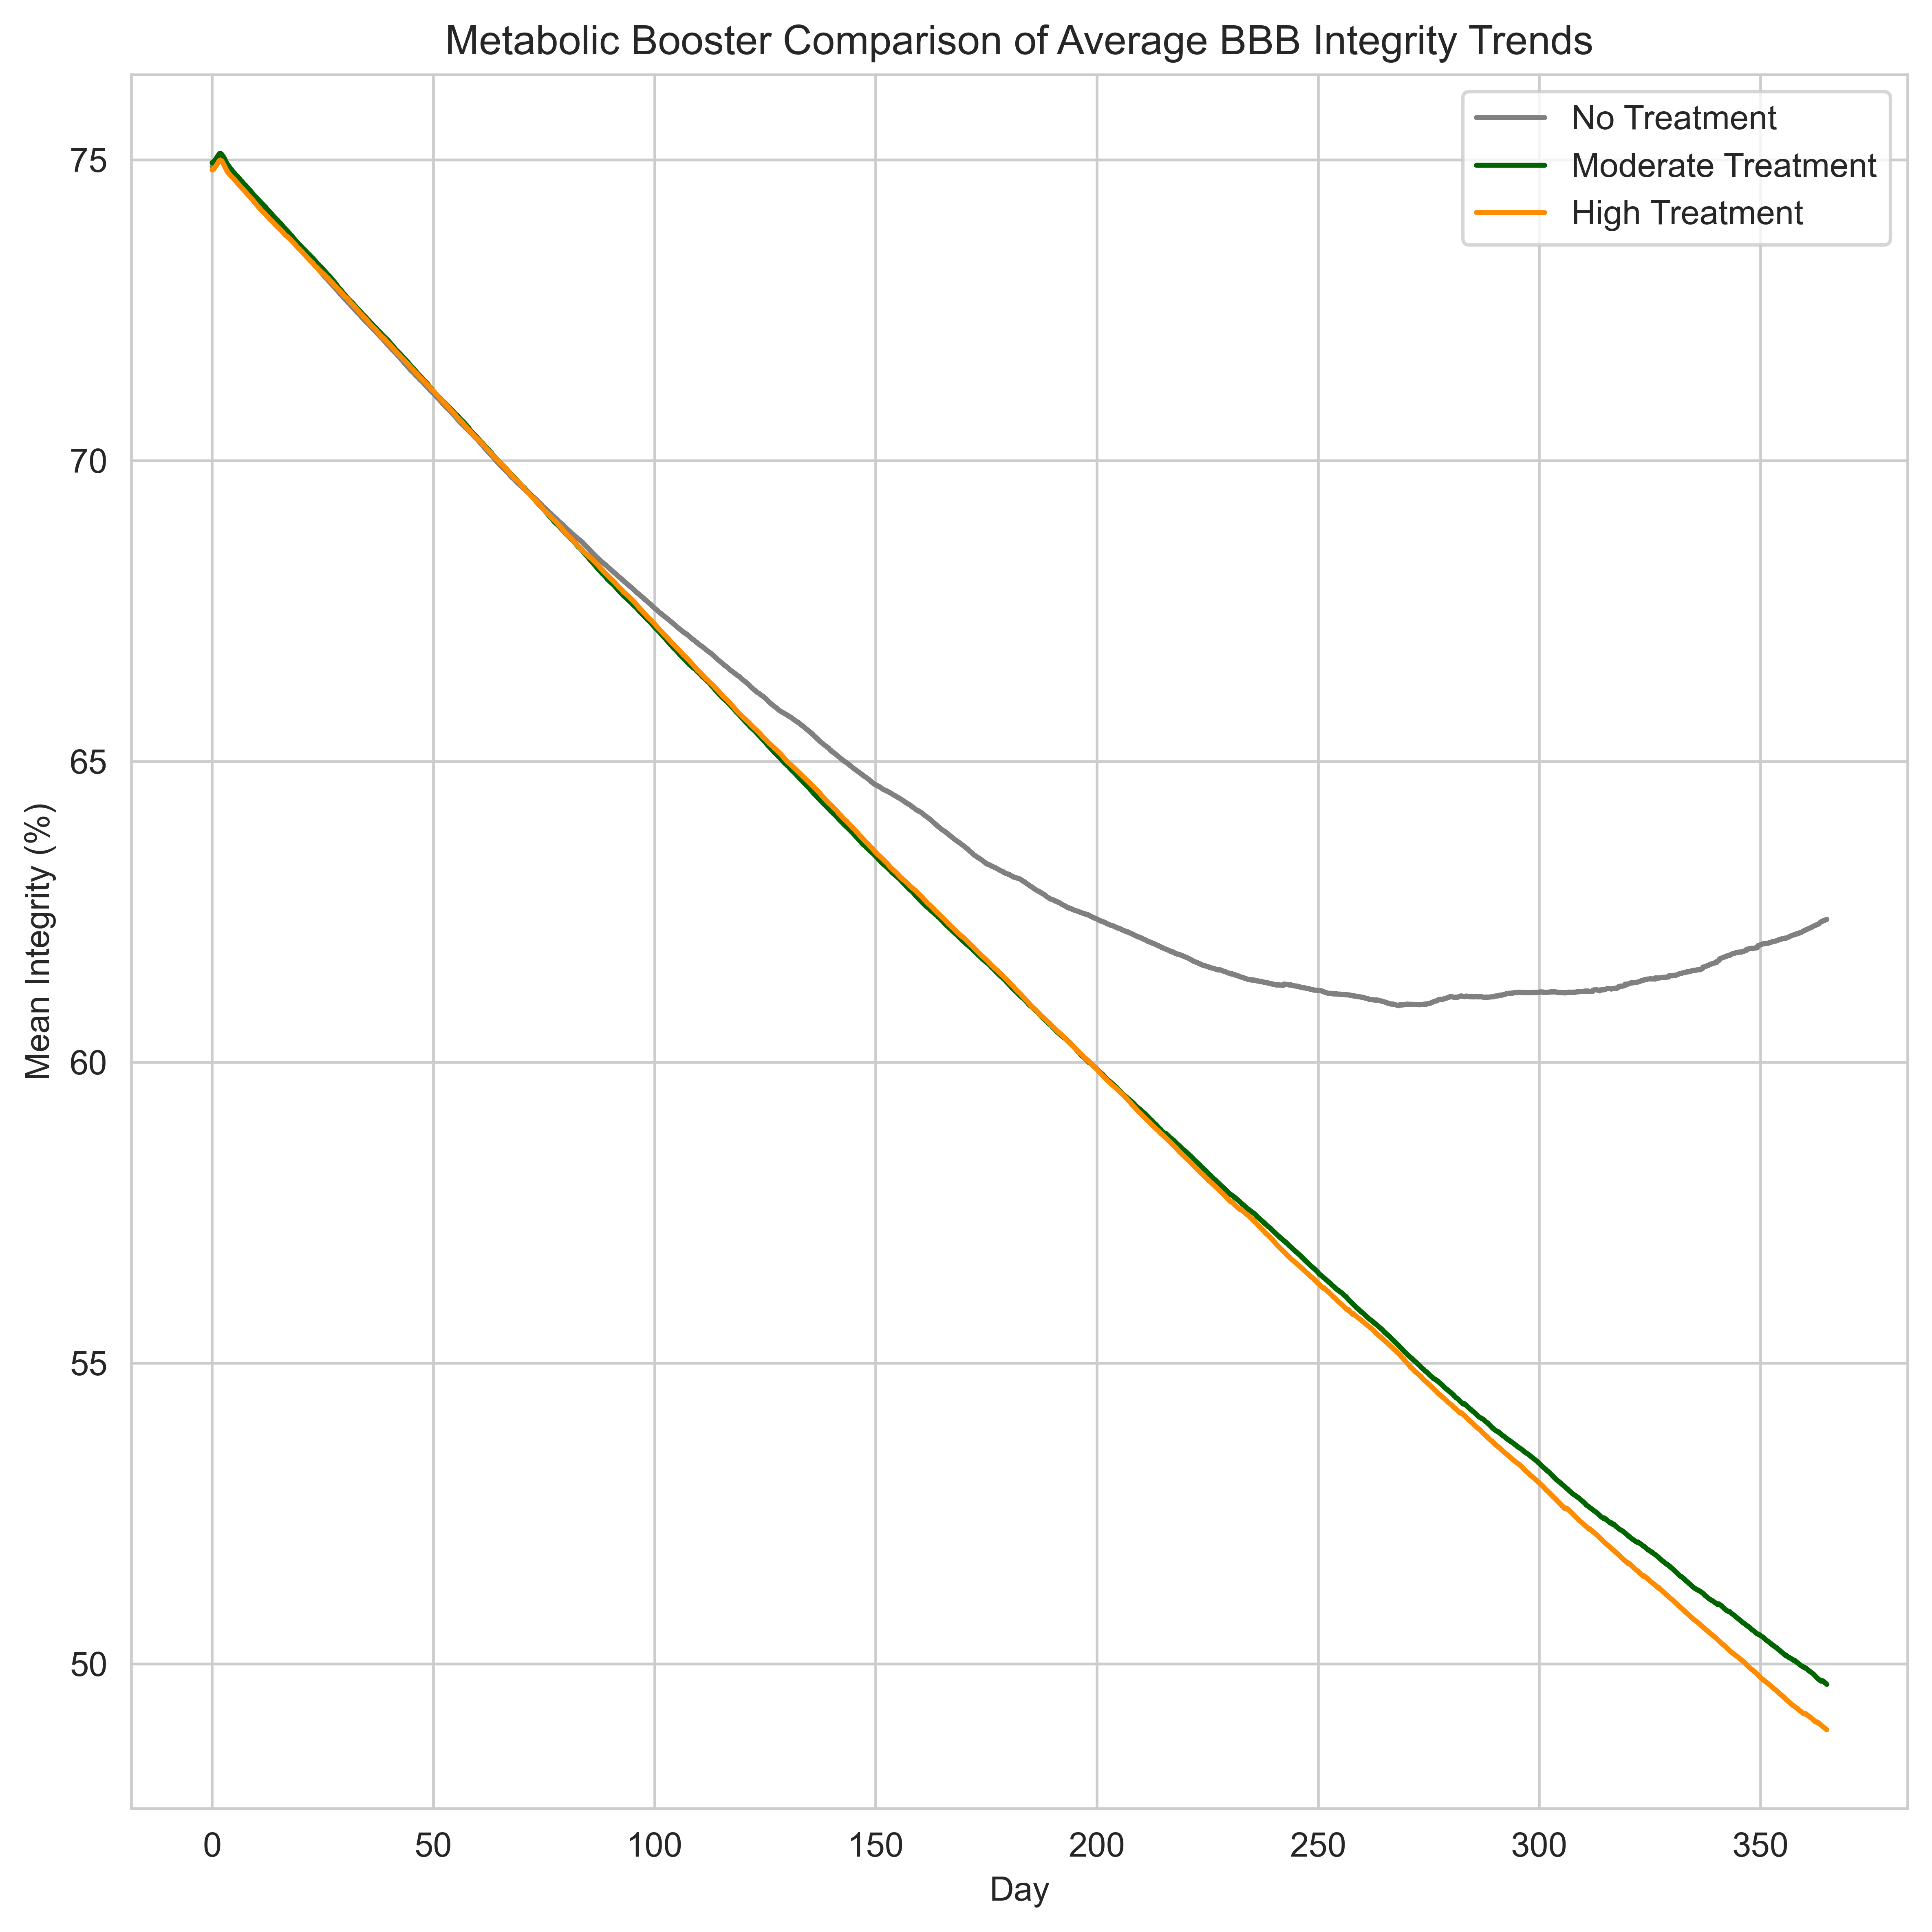

In [29]:
# plot data
fig, ax = plt.subplots(figsize=(8,8))

sns.lineplot(plot_df, x='day',y='none_mean', label='No Treatment',color='grey')
sns.lineplot(plot_df, x='day',y='mid_mean', label='Moderate Treatment',color='darkgreen')
sns.lineplot(plot_df, x='day',y='high_mean', label='High Treatment',color='darkorange')

plt.title('Metabolic Booster Comparison of Average BBB Integrity Trends')
plt.ylabel("Mean Integrity (%)")
plt.xlabel('Day')
plt.tight_layout()